<a href="https://colab.research.google.com/github/Plabon-Basak/ApnoAI/blob/main/ApnoAI_Task_2_Plabon_Basak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 🌸 APNOAI TASK 2: Train Your First ML Model
# Today you'll train a model to identify iris flowers!
# Dataset: 150 flowers, 3 species, 4 measurements each

# Step 1: Import the tools we need
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt

print("✅ All libraries imported successfully!")
print("📚 We're using: scikit-learn (ML), pandas (data), matplotlib (charts)")

✅ All libraries imported successfully!
📚 We're using: scikit-learn (ML), pandas (data), matplotlib (charts)


In [ ]:
# Step 2: Load the famous Iris dataset
# This is the "Hello World" of Machine Learning - used since 1936!

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

print(" Dataset Info:")
print(f"Total flowers: {len(df)}")
print(f"Features: {list(iris.feature_names)}")
print(f"Species: {list(iris.target_names)}")
print("\n🌸 First 5 flowers:")
df.head()

 Dataset Info:
Total flowers: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

🌸 First 5 flowers:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


##  Think Before We Code

Look at the output above and answer:

1. **How many flowers are in the dataset?**: 150

2. **What are the 4 features (measurements)?**
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)
3. **How many species (types) of iris?**: 3 (setosa, versicolor, virginica)

4. **Why do you think this dataset is perfect for beginners?**
   : Iris is perfect for beginners because it’s small (150 flowers), so models train instantly and I can rerun experiments as often as I want. It’s also clean, with no missing values, so I can focus on learning train/test splitting instead of fixing data. Finally, the patterns are clear: the 4 measurements separate the 3 species well, so even a simple Decision Tree can learn them. My model reached 100% test accuracy on a 30-flower test set, which shows how learnable the data is.

**Hint:** Small, clean, no missing values, clear patterns!

In [ ]:
# Cell 4: Split data into Train and Test
from sklearn.model_selection import train_test_split

X = df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data Split Complete!")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Split ratio: 80% train / 20% test")

Data Split Complete!
Training samples: 120
Testing samples: 30
Split ratio: 80% train / 20% test


In [ ]:
# Cell 5: Experiment 1
for ts in [0.1, 0.2, 0.4, 0.5]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=ts, random_state=42)
    m = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
    print(f"test_size={ts}: train samples={len(Xtr)}, test samples={len(Xte)}, "
          f"train acc={m.score(Xtr, ytr):.3f}, test acc={m.score(Xte, yte):.3f}")

test_size=0.1: train samples=135, test samples=15, train acc=1.000, test acc=1.000
test_size=0.2: train samples=120, test samples=30, train acc=1.000, test acc=1.000
test_size=0.4: train samples=90, test samples=60, train acc=1.000, test acc=0.967
test_size=0.5: train samples=75, test samples=75, train acc=1.000, test acc=0.907


**Reliability check at test_size=0.1**

In [ ]:
for seed in [0, 1, 7, 42, 99]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.1, random_state=seed)
    m = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
    print(f"seed={seed}: test acc={m.score(Xte, yte):.3f} on {len(Xte)} samples")

seed=0: test acc=1.000 on 15 samples
seed=1: test acc=1.000 on 15 samples
seed=7: test acc=0.867 on 15 samples
seed=42: test acc=1.000 on 15 samples
seed=99: test acc=0.933 on 15 samples


## Compared a second model (Random Forest)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

for seed in [0, 1, 7, 42, 99]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    dt = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
    rf = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
    print(f"seed={seed}: DT={dt.score(Xte, yte):.3f}  RF={rf.score(Xte, yte):.3f}")

seed=0: DT=1.000  RF=1.000
seed=1: DT=0.967  RF=0.967
seed=7: DT=0.900  RF=0.867
seed=42: DT=1.000  RF=1.000
seed=99: DT=0.933  RF=0.933


## My Experiments

**Changing test_size** (Decision Tree, random_state=42):

| test_size | train / test samples | train accuracy | test accuracy |
|---|---|---|---|
| 0.1 | 135 / 15 | 100% | 100% |
| 0.2 | 120 / 30 | 100% | 100% |
| 0.4 | 90 / 60 | 100% | 96.7% |
| 0.5 | 75 / 75 | 100% | 90.7% |

- Training accuracy stayed at 100% every time, but test accuracy dropped as test_size grew (100% → 96.7% → 90.7%). With less data to learn from, the tree generalised a bit worse to unseen flowers.
- At test_size=0.1 the test set is only 15 flowers. Across 5 different seeds the accuracy ranged from 86.7% to 100%, so a single score on such a small test set is not reliable.
- At test_size=0.5 the model trained on only 75 flowers (half the data), yet still memorised them (100% train) while test accuracy fell to 90.7%.

**Second model (Random Forest vs Decision Tree, test_size=0.2, 5 seeds):**
- They gave identical accuracy on 4 of 5 seeds. On seed 7 the Decision Tree scored 0.900 and the Random Forest 0.867, a difference of just one flower out of 30.
- A one-flower gap on 30 test samples is within noise, so I can't claim either model is better on Iris. The dataset is so easy that a more complex model doesn't help.

## 🤔 Think About It

1. If test_size=0.5, how many samples for training? : 75
2. If test_size=0.1, is the test reliable? Why? : Not very. A 10% test set is only 15 flowers, so each wrong prediction moves accuracy by about 6.7 percentage points (1/15). The score can also change a lot depending on which 15 flowers land in the test set, so one number from one split doesn’t tell you much.
3. Why do we use `random_state=42`? : It fixes the random shuffle, so the split is the same every time you run the cell. That makes your results reproducible: you, your mentor, and anyone else running the notebook get the same train/test sets and the same accuracy. The number 42 itself has no special meaning. Any fixed number works.

In [ ]:
# Cell 6: Train Decision Tree Model
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Accuracy: {train_acc*100:.1f}%")
print(f"Testing Accuracy: {test_acc*100:.1f}%")

Training Accuracy: 100.0%
Testing Accuracy: 100.0%


## 🤔 Think About It

1. Is 96% testing accuracy good? Why? : Yes, on Iris it’s good. Test accuracy measures performance on flowers the model never saw during training, and 96% on 30 test flowers means about 1 or 2 mistakes. It’s most convincing when training accuracy is close to it, because that shows the model learned real patterns instead of memorizing. Also keep the small test set in mind: with only 30 samples, one extra mistake changes the score by about 3 points.
2. What if training=100% but testing=60%? : The model memorized the training data instead of learning general patterns. It performs perfectly on flowers it has already seen but badly on new ones, so it would fail in real use. The large gap between the two numbers is the warning sign.
3. What is this problem called? : Overfitting.

**My own result:** my model got 100% on both training and testing (test_size=0.2, random_state=42), so there is no overfitting on that split. Because a 30-flower test set is small, I also checked other settings and seeds below before trusting that number.

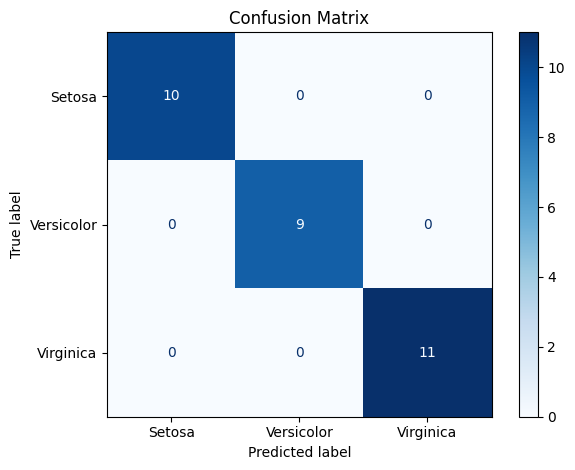

In [ ]:
# Cell 8: Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, model.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Setosa', 'Versicolor', 'Virginica'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

[[29  0  0]
 [ 0 20  3]
 [ 0  4 19]]


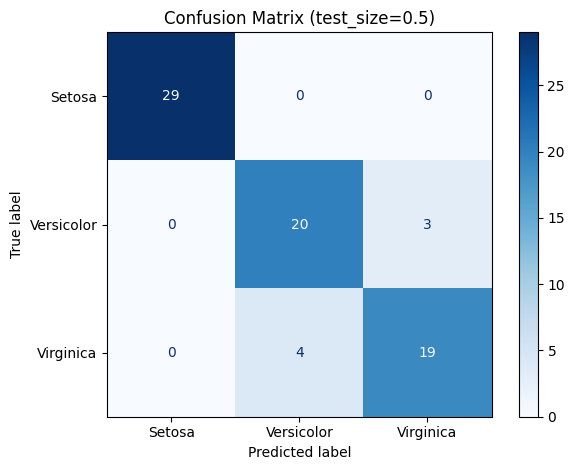

In [ ]:
# Confusion matrix at test_size=0.5 (where the model actually makes mistakes)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, random_state=42)
m = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)
cm05 = confusion_matrix(yte, m.predict(Xte))
print(cm05)
ConfusionMatrixDisplay(cm05, display_labels=['Setosa', 'Versicolor', 'Virginica']).plot(cmap='Blues')
plt.title('Confusion Matrix (test_size=0.5)')
plt.tight_layout()
plt.show()

**Reading the two confusion matrices:** at test_size=0.2 every prediction is on the diagonal (no mistakes), so it can't show where the model fails. At test_size=0.5 the model makes 7 mistakes out of 75: 3 versicolor predicted as virginica and 4 virginica predicted as versicolor. Setosa is 29/29 correct.

# 📝 Your 3 Key Insights

## Insight 1: About Train/Test Split
Test size changes how much I can trust a score. Going from test_size=0.1 to 0.5, training samples dropped from 135 to 75 and test accuracy fell from 100% to 90.7%. At test_size=0.1 there are only 15 test flowers, and different seeds gave anywhere from 86.7% to 100%, so one 100% score does not prove the model is perfect. test_size=0.2 (30 test flowers) was a reasonable balance between enough training data and a usable test set.

## Insight 2: About Model Accuracy
Training accuracy was 100% in every run, while test accuracy ranged from 90.7% to 100%. At test_size=0.2 the train/test gap is 0, so there is no overfitting on that split. At test_size=0.5 the gap is about 9 points: the tree fits its training data perfectly but does a bit worse on unseen flowers, which is an early sign of overfitting. Random Forest matched the Decision Tree on 4 of 5 seeds, so a more complex model did not help on this easy dataset.

## Insight 3: About Confusion Matrix
At test_size=0.2 my confusion matrix was perfect, so it showed no failures. At test_size=0.5 the model made 7 mistakes out of 75, and all of them were between versicolor and virginica (3 versicolor predicted as virginica, 4 the other way), while setosa was 29/29 correct. This suggests setosa is easy to separate and versicolor and virginica have more similar measurements. Accuracy alone (90.7%) would not tell me which classes get confused; the confusion matrix does.